# Lights On, Oil Off

### Does Newfoundland need a new oil-burning turbine to retire Holyrood?

Qiskit Fall Fest 2026, Memorial University. Theme: Quantum for a Sustainable Newfoundland and Labrador.
Team details are in `submit_info.md`.

The Holyrood plant on Conception Bay burns heavy oil and put out roughly 600,000 tonnes of CO2 a year in 2022 to 2024.
It is due to retire around 2030. To replace it, NL Hydro has asked the regulator to approve two projects: a 150 MW
unit at Bay d'Espoir (Unit 8, about CAD 1.08 billion) and a 150 MW combustion turbine at Holyrood that burns diesel
(about CAD 1 billion). The alternative people keep bringing up is wind and heat pumps.

Whatever gets built has to keep the lights on in a cold snap. Most people here remember DarkNL in January 2014, when
about 190,000 customers lost power, and in January 2026 frazil ice shut down every unit at Bay d'Espoir at once. NL
Hydro plans to a simple rule: expected blackout time must stay under 2.8 hours a year.

We built a model of the island grid from public data and used it to ask the turbine question directly.

**The short answer**

* If the Labrador-Island Link keeps the record it had over the last 12 months (out 1.1% of the time), the turbine
  isn't needed. Unit 8, 200 MW of new wind, heat pumps in 90,000 homes and 40 MW of smart thermostats stays under the
  limit (1.75 h a year), and costs about the same per year as the cheapest passing plan that uses the turbine instead
  (CAD 66.6M vs 64.4M).
* The turbine is really insurance against the link. Our strongest plan without it is safe until the link is out 3.3%
  of the winter. Add the turbine and it holds past 5%, the rate Hydro uses for planning. So the decision comes down to
  how much you trust the link.
* Each of those answers is a small probability sitting close to the limit, and that is where the quantum part fits.
  Near the limit, quantum amplitude estimation needs 2 to 3 times fewer samples than the best classical sampler we
  could build, and about 60 times fewer than plain Monte Carlo, to call "pass" or "fail" with confidence. That is for an
  ideal quantum computer; far from the limit the classical sampler is cheaper.
* On IBM's ibm_quebec chip the circuit works, and with calibration it ties Monte Carlo on shallow circuits. It does not
  beat it yet.

| Step | What it does | Method |
|---|---|---|
| 1 | Learn hourly island demand from the weather (4 years of NL Hydro data) | AI: gradient-boosted trees |
| 2 | Replay 46 winters of weather (1980 to 2025) through that model | classical |
| 3 | Turn demand and power plant breakdown odds into blackout hours, and check against NL Hydro | classical |
| 4 | Score 4,096 plans for 2030 and find how much link trouble each one can take | classical |
| 5 | Put a plan's whole risk picture into one quantum state and estimate its blackout probability | quantum amplitude estimation |
| 6 | Run the same circuit on real IBM hardware | quantum, real chip |

## Setup

Every number below is read from `results/`, so the notebook runs in about a minute. Set `RECOMPUTE = True` to rerun all
the experiments from scratch (about 45 minutes, and the data downloads on the first run).

In [1]:
import sys
from pathlib import Path
import pandas as pd
import qiskit, qiskit_aer, sklearn

sys.path.insert(0, str(Path.cwd()))
from gridrisk import plots, report

pd.set_option("display.max_colwidth", 200)
print("qiskit", qiskit.__version__, "| qiskit-aer", qiskit_aer.__version__, "| scikit-learn", sklearn.__version__)

RECOMPUTE = False
if RECOMPUTE:
    import runpy
    for name in ["e1_demand_model", "e2_reliability", "e3_quantum_core", "e4_rarity_advantage", "e5_hardware_scale", "e6_cold_snap"]:
        runpy.run_path(f"experiments/{name}.py", run_name="__main__")
    from experiments import e7_every_good_plan as e7, turbine_decision
    e7.stage_tables(); turbine_decision.run()

qiskit 2.6.2 | qiskit-aer 0.18.2 | scikit-learn 1.9.1


## 1. Learning the island's demand from the weather

NL Hydro publishes island demand every five minutes and Statistics Canada archives it: 373,000 readings since
September 2022. We trained gradient-boosted trees on it, using weather at St. John's, Gander and Corner Brook from the
ERA5 reanalysis (temperature and its recent history, dew point, wind, sun, snow), plus hour, weekday and holidays.

Trees can't extrapolate, and the coldest winters in our 46-year replay are colder than anything in the training data.
So below the coldest training temperature, our model keeps rising at the slope of the coldest 5% of hours. We trained on
September 2022 to August 2025 and tested on the 2025-26 winter, which the model never saw.

,"held-out winter, MAPE %","daily peak, MAPE %","top 1% hours, MAE MW","colder than training, MAE MW","4 Feb 2023 record (actual 1,980 MW), predicted MW"
linear degree-hour (utility standard),6.6,5.4,61.1,79.9,1595.1
boosted trees,5.7,5.2,63.0,79.8,1657.2
boosted trees + cold tail (ours),5.7,5.2,63.0,40.8,1657.2


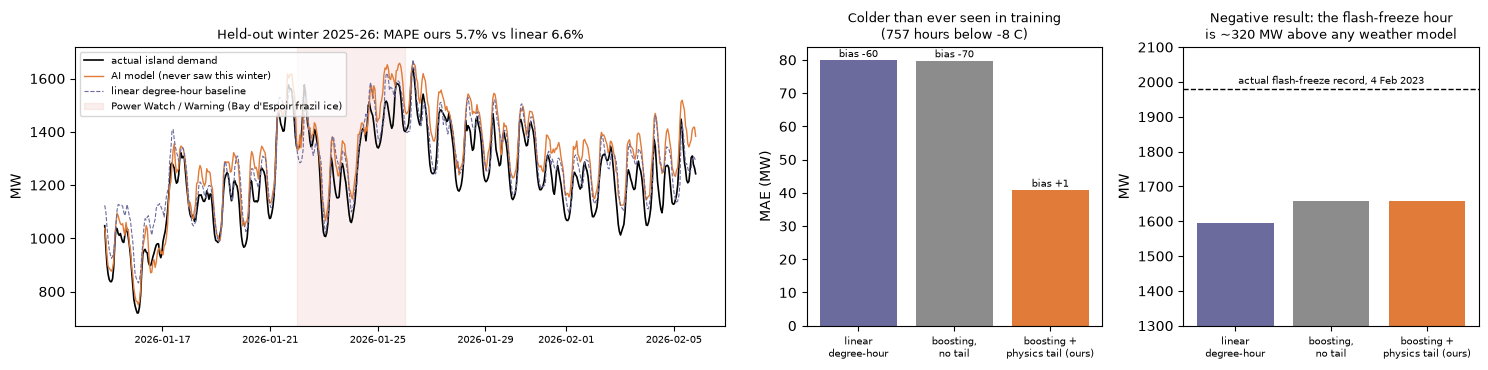

In [2]:
display(report.ai())
plots.show("demand_model")

The model beats the degree-hour regression utilities usually use (5.7% vs 6.6% hourly error on the unseen winter). The
cold tail matters where it should: on hours colder than anything in training, error drops from 80 MW to 41 MW.

It doesn't fix everything. On 4 February 2023 the temperature fell from +2 C to -11 C in ten hours and demand set a
record of about 1,980 MW. Every model, ours included, misses it by about 320 MW. So we don't trust a single forecast in
the tail. The reliability engine below draws from the model's real out-of-sample errors instead, which puts surprises
like that one into the risk.

## 2. Forty-six winters, and a surprise about the wind

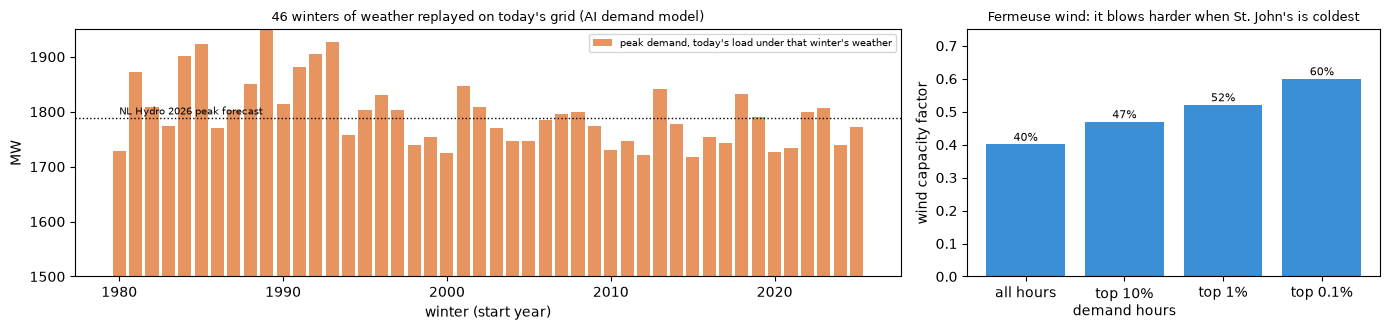

In [3]:
plots.show("winters_and_wind")

We ran every winter since 1980 through the model at today's load. The worst years for today's grid are in the early
1990s, colder than anything since, and a study of recent winters alone would miss them.

The surprise is that St. John's coldest hours tend to be windy. A wind farm near Fermeuse would run at about 60% of its
capacity in the 0.1% highest-demand hours, against 40% on average. (ERA5 winds at 100 m and a generic 3 MW turbine that
shuts down below -20 C. We don't model icing, so this is on the optimistic side.)

## 3. Does our model agree with NL Hydro?

For every hour of the 46 winters we compute the chance that the available power plants can't cover demand, after the
forecast error and the wind. Plant breakdown odds are NL Hydro's planning values, combined exactly. Adding this up over
a winter gives the expected blackout hours (loss-of-load hours). Hydro publishes the same number for the coming winter,
so we can check ourselves against it.

In [4]:
report.validation()

,ours (h/yr),NL Hydro (h/yr)
"2026-27 grid, Holyrood at its planning outage rate (20%)",1.63,1.8
"same, Holyrood as bad as winter 2021-22 (34%)",3.74,4.1


Built from public data only, we land within about 10% of Hydro's own numbers in both cases, slightly on the optimistic
side. That agreement is the main reason we trust the engine for the questions below.

## 4. Heat pumps: which homes go first matters

,change at the coldest hour (MW),change at a typical winter peak (MW),blackout hours / yr
"today, no change",0.00,0.00,1.63
40k oil homes -> heat pump,120.04,70.01,2.66
"40k oil homes -> heat pump, oil furnace kept below -10 C",0.00,0.00,2.05
50k baseboard homes -> heat pump,-53.55,-68.43,0.78


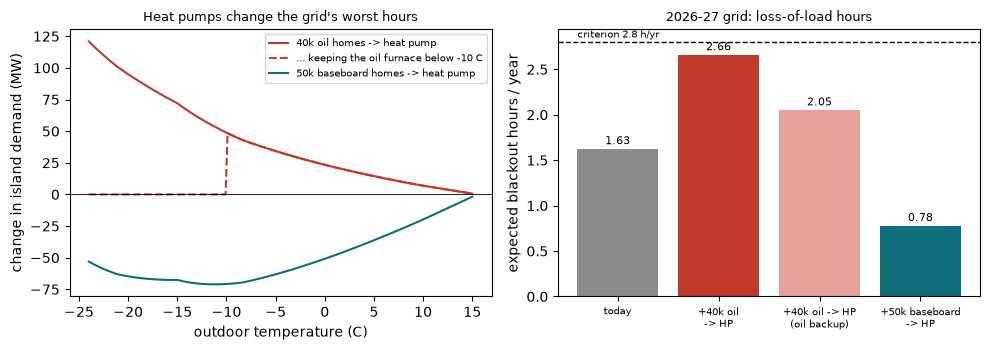

In [5]:
display(report.heat_pumps())
plots.show("heat_pumps")

Moving 40,000 oil-heated homes to heat pumps cuts about 260,000 tonnes of CO2 a year. But it adds 70 to 120 MW to the
grid's coldest hours and pushes blackout time from 1.6 to 2.7 hours a year, right up against the limit. Keeping the oil
furnace as a backup below -10 C removes most of that.

Converting 50,000 baseboard-heated homes does the opposite. A heat pump uses less electricity than a baseboard heater
for the same heat, so demand at the peak drops by about 70 MW and blackout time halves.

## 5. Do we need the turbine?

We gave the model twelve yes-or-no options for the first winter after Holyrood's oil units retire (2030, with Hydro's
peak forecast of 1,860 MW):

* the Holyrood turbine and Bay d'Espoir Unit 8;
* 100 MW of wind at each of three sites (near Fermeuse, St. Lawrence and Port au Port);
* a 25 MW and a 50 MW battery;
* heat pumps for 15,000 or 35,000 baseboard homes and for 10,000 or 30,000 oil homes;
* 40 MW of smart thermostats that can be turned down at the peak.

That makes 4,096 plans. Each one gets blackout hours from the engine above, and a yearly cost: capital and running
costs, minus household bill savings and the value of the wind energy, plus CO2 at CAD 170 a tonne and a cost for
blackouts. The turbine, Unit 8 and battery costs come from Hydro's filings; the rest are our assumptions, listed in
`gridrisk/portfolio.py`.

The biggest unknown is the Labrador-Island Link, the 700 MW line from Muskrat Falls. Over the 12 months to September
2026 it was out 1.1% of the time, but Hydro plans as if it will be out 5%. So instead of picking one number, we asked
how much link trouble each plan can take (`experiments/turbine_decision.py`).

,built,"blackout h/yr, link 1.1%","blackout h/yr, link 5%",safe up to a link outage rate of
Hydro's plan: Unit 8 + turbine,"turbine, Unit 8",1.91,8.67,1.6%
cheapest plan without the turbine,"Unit 8, wind Avalon, wind Burin, 15k baseboard homes, 35k baseboard homes, 10k oil homes, 30k oil homes, smart thermostats",1.75,7.94,1.8%
strongest plan without the turbine,"Unit 8, wind Avalon, wind Burin, wind west coast, battery 25 MW, battery 50 MW, 15k baseboard homes, 35k baseboard homes, smart thermostats",0.92,4.20,3.3%
"same, plus the turbine","turbine, Unit 8, wind Avalon, wind Burin, wind west coast, battery 25 MW, battery 50 MW, 15k baseboard homes, 35k baseboard homes, smart thermostats",0.20,0.90,beyond 5%


,"cheapest passing plan with the turbine, CAD M/yr","cheapest passing plan without it, CAD M/yr",plans that pass without the turbine
link 1.1% (measured),64.4,66.6,543
link 3%,128.5,126.8,4
link 5% (Hydro planning),141.5,none passes,0


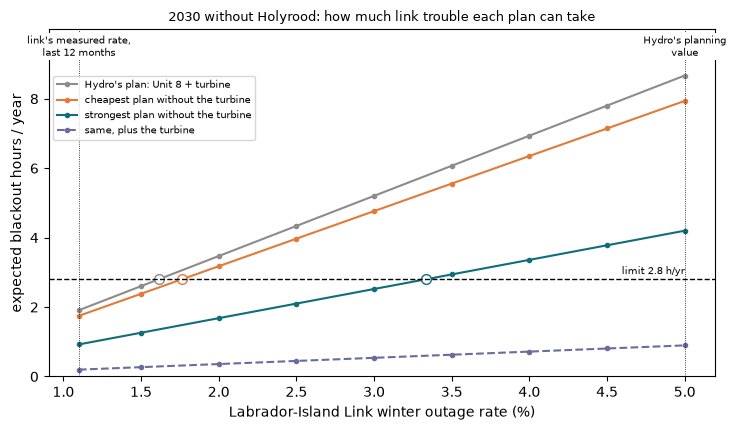

In [6]:
reach, cost = report.turbine()
display(reach, cost)
plots.show("turbine")

Each line is a plan, and the circle marks where it crosses the 2.8 h limit.

* **At the link's recent rate, the turbine isn't needed.** The cheapest passing plans with and without it are almost the
  same: both build 200 MW of wind, heat pumps in 90,000 homes and the smart thermostats, and one has the turbine where
  the other has Unit 8. They cost CAD 64.4M and 66.6M a year, and the one without the turbine emits about 10,000 tonnes
  less CO2.
* **The turbine buys tolerance for a bad link.** Our strongest plan without it (Unit 8, wind at all three sites, both
  batteries, 50,000 baseboard conversions, smart thermostats) is safe until the link is out 3.3% of the time. Add the
  turbine and it stays under one hour a year even at 5%.
* Hydro's two projects on their own cross the limit at 1.6% in our model. Hydro's own studies include things ours leaves
  out (see Limitations), so we read this as "the turbine alone doesn't settle it", not as a verdict on their plan.

So the answer to our title is that it depends on the link, and the break-even is about 3%. If the link keeps performing
the way it did last year, wind and heat pumps can replace Holyrood's oil without building new diesel.

## 6. Why this is a quantum problem

Every number in the last section is a small probability: the chance that a random winter hour is short of power,
somewhere between 1 in 1,000 and 1 in 10,000. Estimating a small probability by sampling is expensive. With Monte
Carlo, the number of samples needed for a relative error $\varepsilon$ grows like $1/(p\,\varepsilon^2)$. The safer the
grid, the more samples it takes to prove it's safe, and halving the error costs four times as many samples.

Quantum amplitude estimation (Brassard et al. 2002) does the same job with about $1/(\sqrt{p}\,\varepsilon)$ runs of a
circuit, so halving the error only doubles the cost. We borrowed the setup from quantum credit-risk analysis (Woerner
and Egger 2019): power plants play the part of loans that might default, demand is the loss threshold, and cold weather
is the hidden factor that makes failures happen together.

Our circuit $A$ has four parts:

1. Five qubits hold demand minus wind minus the small plants, in 32 steps of 50 MW, with probabilities from the AI and
   the 46 winters.
2. One qubit per big unit (the Labrador link, Bay d'Espoir Unit 7, Hardwoods, and any new units in the plan) is rotated
   so that it reads "broken" with that unit's outage rate.
3. One more qubit stands for a January-2026-style frazil shutdown of Bay d'Espoir. Its rotation is controlled by the
   demand qubits, so it happens more often on cold nights. Correlated failures like this break the shortcut that
   classical methods rely on; here they cost one controlled rotation.
4. A quantum adder sums the lost capacity for every combination at once, and a comparator flips a flag qubit when supply
   falls short.

The chance that the flag reads 1 is the blackout risk $p$. Amplitude estimation runs $A$ followed by $m$ "boosts"
(Grover iterations) for a few values of $m$. The flag then reads 1 with probability $\sin^2((2m+1)\theta)$, where
$\sin^2\theta = p$, and a maximum-likelihood fit recovers $p$ (Suzuki et al. 2020).

## 7. A small version you can run

The full circuit has 24 qubits and thousands of gates, which is far too deep for today's chips. For the hardware runs
we made an exact 3-qubit version of a real case (2030, Holyrood retired, nothing added, link out 5%): qubit 0 is "high
demand hour", qubit 1 is "link down" and qubit 2 is "short of power", with the odds for qubit 2 worked out exactly from
the rest of the fleet. It has the same blackout probability as the full model: 2.1% of winter hours.

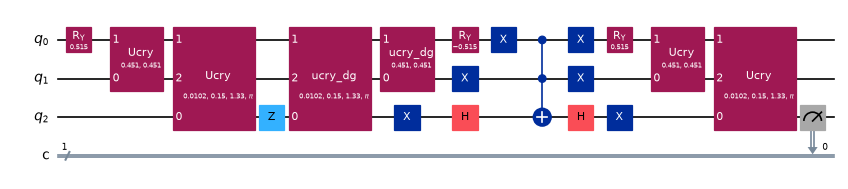

In [7]:
from qiskit.quantum_info import Statevector
from gridrisk.quantum import load_reduction, three_qubit_circuits

small = load_reduction(report.load("e5_hardware_scale_noise.json")["reduction"])
circuits = three_qubit_circuits(small, powers=[0, 1, 2, 3, 4])
circuits[1].draw("mpl", scale=0.6)

In [8]:
flag = [Statevector(c.remove_final_measurements(inplace=False)).probabilities([2])[1] for c in circuits]
pd.Series(flag, name="P(flag = 1)").rename_axis("boosts").round(3)

boosts
0    0.021
1    0.181
2    0.448
3    0.731
4    0.938
Name: P(flag = 1), dtype: float64

With no boost the flag is 1 about 2% of the time, which is the blackout risk itself. Each boost turns the state further
towards the flagged outcomes, so the signal climbs quickly. Measuring that climb is what lets amplitude estimation pin
down a small $p$ with fewer runs than counting rare events one by one.

## 8. Does the full circuit give the right answer?

Next, the full 24-qubit circuit for today's grid, simulated in Qiskit Aer. We compare its exact output with a classical
enumeration of the same model, then do real amplitude estimation runs (300 repeats, up to 32 boosts) against Monte Carlo
with the same number of samples.

,
qubits,24
two-qubit gates in A / in one boost,"1,586 / 5,198"
"P(blackout hour), circuit",5.861573e-04
"P(blackout hour), classical enumeration",5.861573e-04
"blackout h/yr, circuit vs full engine",1.71 vs 1.71
"error at 13,300 samples, amplitude estimation vs Monte Carlo",4.4% vs 35.8%


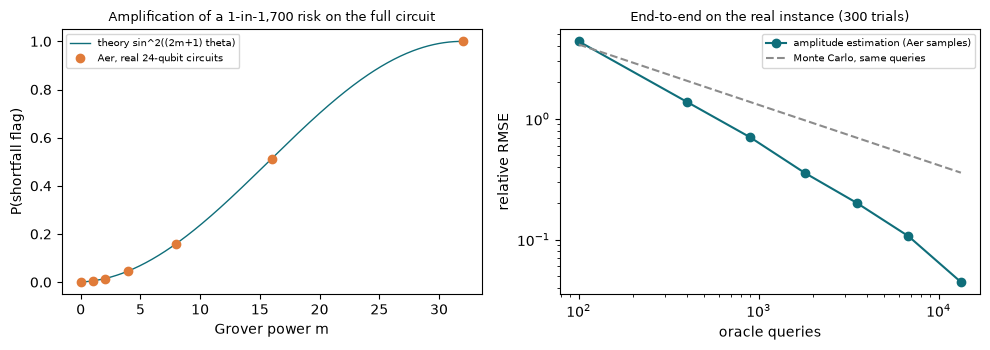

In [9]:
display(report.core())
plots.show("core_check")

The circuit matches the classical answer to every digit shown. With 13,300 samples, amplitude estimation is within 4.4%
of the truth on average, while Monte Carlo with the same budget is off by 36%.

## 9. How many samples does a confident answer take?

Two comparisons. The first uses a fixed 10% precision across nine grid situations from sections 3 to 5. The second is
the turbine decision itself: the strongest plan without the turbine, at link outage rates around its break-even. To
call pass or fail with about 95% confidence, the error has to be within half the distance to the 2.8 h line (we stop at
1%).

The classical competitor is importance sampling, which deliberately oversamples breakdowns and cold hours and then
corrects for it. We tuned it by trying 30 settings and keeping the one with the lowest true variance, which is more help
than a real study would have. Amplitude estimation counts are for an ideal, noise-free quantum computer, from 300
simulated runs per budget.

,blackout h/yr,Monte Carlo,importance sampling,amplitude estimation
"2030 Holyrood retired, nothing added (link 5%)",62.06,"4,588","1,622","1,069"
"2030 Holyrood retired, nothing added (link 1.1%)",14.53,"19,916","6,773","2,484"
2030 Hydro's plan (link 5%),8.79,"32,984","2,448","2,923"
"2026-27 system, Holyrood at 34% outage rate",3.84,"75,673","3,426","4,927"
2026-27 system,1.71,"170,503","5,936","7,011"
2030 Unit 8 + 300 MW wind + 50k heat pumps (link 1.1%),1.63,"178,138","9,844","7,473"
2030 Unit 8 + 600 MW wind + 50k heat pumps (link 1.1%),1.09,"266,942","10,485","9,403"
2026-27 system + 50k heat pumps,0.85,"343,633","9,951","10,611"
2026-27 system + 50k heat pumps + 300 MW wind,0.33,"885,307","9,139","18,609"


,blackout h/yr,precision needed,Monte Carlo,importance sampling,amplitude estimation
link 1.1%,0.96,96.0%,"3,292",119,805
link 2.0%,1.73,31.0%,"17,533",675,"2,235"
link 2.5%,2.16,14.9%,"60,625","2,321","4,245"
link 3.0%,2.58,4.2%,"647,453","24,603","14,330"
link 3.2%,2.76,1.0%,"10,547,538","442,687","182,989"
link 3.4%,2.93,2.2%,"2,117,278","82,477","24,057"
link 3.6%,3.10,4.8%,"405,875","15,623","10,710"
link 4.0%,3.44,9.3%,"97,598","4,210","5,560"
link 4.5%,3.87,13.8%,"39,421","1,772","3,554"


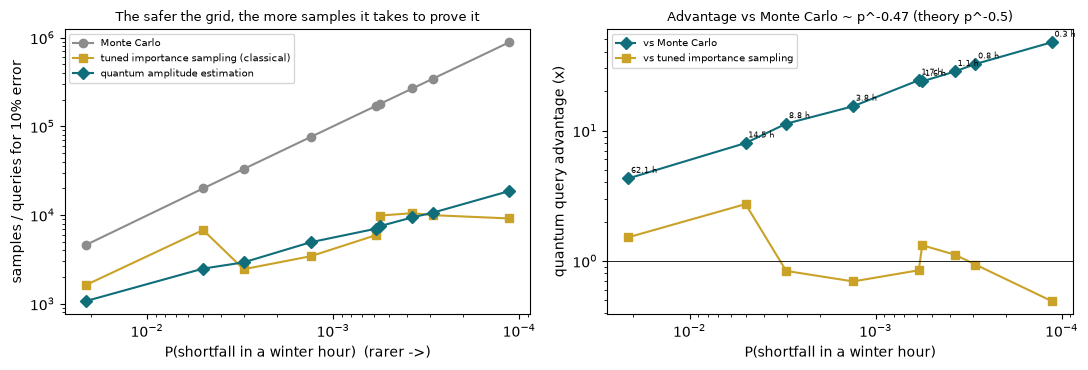

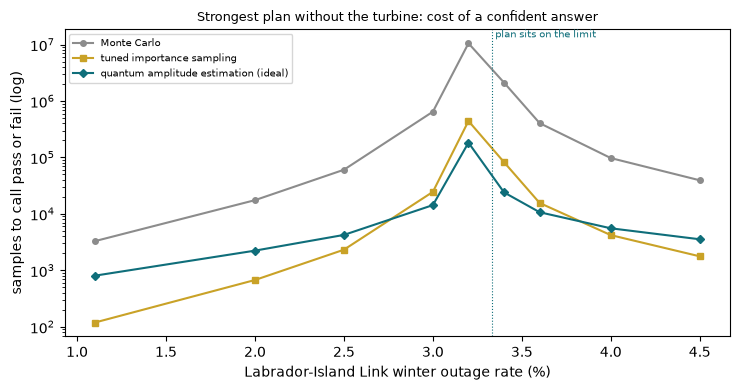

In [10]:
fixed, decision = report.samples()
display(fixed, decision)
plots.show("rarity_advantage", "decision_samples")

At 10% precision, amplitude estimation needs 4 to 48 times fewer samples than Monte Carlo, and the gap grows as the
grid gets safer, close to the $1/\sqrt{p}$ the theory predicts. Against tuned importance sampling it's roughly even at
that precision (anywhere from 2.7 times better to 2 times worse).

The decision table is where it gets interesting. Far from the line, a rough estimate is enough and importance sampling
is the cheapest. Near the line you need precision, the classical cost grows with its square, and amplitude estimation
pulls ahead. At a 3.4% link rate it needs about 24,000 samples against 82,000 for importance sampling and 2.1 million
for Monte Carlo. Right on the line it needs 183,000, against 443,000 and 10.5 million. Anyone screening thousands of
plans spends most of their effort on borderline ones like these.

These are sample counts, not seconds. For this to save real time, a quantum computer would have to be error-corrected
and fast enough per run.

## 10. On a real IBM quantum computer

We ran the 3-qubit circuits on ibm_quebec, a 156-qubit IBM Heron processor in Bromont, Quebec: 10,000 shots per
circuit split into 10 repeats, with gate twirling and dynamical decoupling switched on.

The first run used the circuits as they were. For the second we added two "twin" circuits with the same gates and
layout but answers we know exactly, one near 0 and one near 1. They show how the chip bends the flag reading at each
number of boosts, so we can undo that before fitting. We report the error two ways: with that calibration shared across
many estimates (it only depends on the circuit's shape), and with its cost charged to every estimate, which triples the
runs.

,Monte Carlo,"ibm_quebec, calibration shared","Monte Carlo, 3x runs","ibm_quebec, calibration paid (3x runs)"
runs,,,,
1000,0.214,0.416,0.124,0.557
4000,0.107,0.091,0.062,0.111
9000,0.071,0.062,0.041,0.064
16000,0.054,0.087,0.031,0.090
25000,0.043,0.089,0.025,0.092


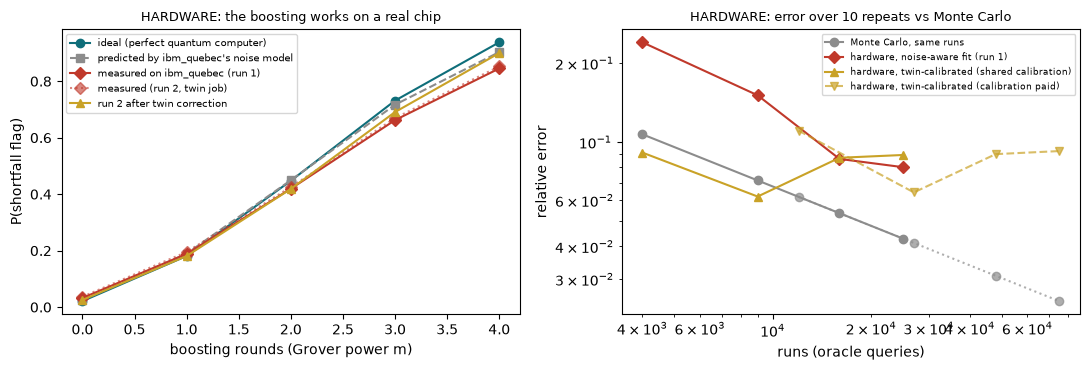

In [11]:
display(report.hardware())
plots.show("hardware_real")

In [12]:
from gridrisk.quantum import mlae_estimate

tw = report.load("e5_hardware_twin.json")
n = tw["shots_per_circuit"]
fit = lambda k: mlae_estimate([round(p * n) for p in tw["corrected_target"][:k + 1]], [n] * (k + 1), list(range(k + 1)))
pd.DataFrame({"estimate from ibm_quebec": [fit(k) for k in range(5)], "truth": tw["p_true"]}).rename_axis("boosts used").round(4)

,estimate from ibm_quebec,truth
boosts used,,
0,0.0255,0.0213
1,0.0217,0.0213
2,0.0203,0.0213
3,0.0198,0.0213
4,0.0195,0.0213


The boosting works on the chip: after correction, the flag climbs from about 2.5% to 90% across four boosts, close to the
ideal curve.
Using up to one boost, the estimate from the chip is 0.0217 against a true 0.0213. More boosts should sharpen it, but the
chip's leftover noise pulls the estimate down instead (0.0195 with all four).

With the calibration shared, the chip ties Monte Carlo on shallow circuits: 9.1% vs 10.7% error at 4,000 runs and 6.2%
vs 7.1% at 9,000. With only 10 repeats those gaps are within the uncertainty, so we call it a tie, not a win. Deeper
circuits leave an error near 9% that the calibration can't remove, and if the calibration runs are charged, Monte Carlo
wins at every budget. Both runs together used 64 seconds of chip time.

## 11. Cold snaps that last for days

A one-hour model treats hours as independent, which is why the exact classical calculation above is fast. Real cold
snaps last days and big outages persist: Bay d'Espoir was down for about four days in January 2026. So we extended the
circuit day by day. A 2-qubit register picks how severe the cold snap is (the worst 3-day stretch of each of the 46
winters, in four classes). For each day, one qubit stands for the link and one for the frazil shutdown, and each is
rotated depending on whether the same unit was down the day before. A final flag records whether any day was short.

,exact,circuit,Monte Carlo (400k),if days were independent,qubits
link 5%,0.0961,0.0961,0.0967,0.1470,22
link 1.1%,0.0287,0.0287,0.0278,0.0411,22


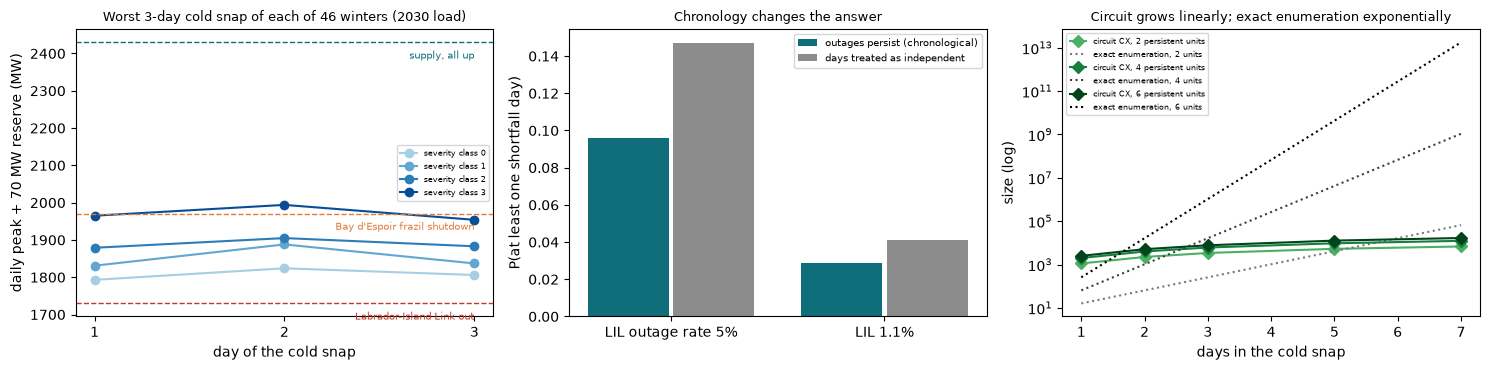

In [13]:
display(report.cold_snap())
plots.show("cold_snap")

The 22-qubit circuit matches exact enumeration and a 400,000-run Monte Carlo. Treating the days as independent
overstates the risk by about half (0.147 vs 0.096 with the link out 5%), because outages bunch together. Exact
enumeration grows exponentially with units times days, while the circuit grows linearly. Models like this are what
planners actually sample, and that's where amplitude estimation's savings would apply. The persistence numbers are our
assumptions, anchored to the 2026 event.

## 12. The bottleneck: checking plans through a cold snap

This is the case a normal computer struggles with. When outages last for days there is no exact shortcut: every plant's
history has to be followed day by day, and the number of possible histories doubles with every plant and every day.
Real planning has about 40 plants over whole winters, so planners can only simulate, and rare events need a lot of runs.

So we applied the quantum method to exactly this model. Four 2030 plans, each with the link down 1.1% and 5% of the
time, through the winter's worst 3-day cold snap. The plans differ in what they build (Unit 8, the turbine, batteries,
smart thermostats, wind counted at its output in the busiest 1% of hours) and in heat pumps, applied at the snap's
coldest temperature. We call a plan safe if the chance of a day short of power stays under 10%, close to the classic
"one day in ten years" reliability standard.

For each check we ran the real 22-qubit circuits with 0, 1, 2, 4 and 8 boosts on Qiskit Aer (20,000 shots each), split
the shots into 200 independent tries of 3,500 runs, and fitted each try. Monte Carlo gets the same 3,500 runs. At this
small size (2 plants over 3 days) we can still enumerate every history exactly, which is how we know the right answers.

,exact risk,quantum estimate,"error, Monte Carlo","error, quantum","right calls, Monte Carlo","right calls, quantum"
"Hydro's plan: Unit 8 + turbine, link 1.1%",2.75%,2.77%,±10%,±5%,200 of 200,200 of 200
"Hydro's plan: Unit 8 + turbine, link 5%",9.51%,9.50%,±5%,±2%,34 of 200,184 of 200
"cheapest plan without the turbine, link 1.1%",1.69%,1.68%,±13%,±4%,200 of 200,200 of 200
"cheapest plan without the turbine, link 5%",7.60%,7.56%,±6%,±2%,200 of 200,200 of 200
"strongest plan without the turbine, link 1.1%",1.50%,1.49%,±14%,±4%,200 of 200,200 of 200
"strongest plan without the turbine, link 5%",6.77%,6.79%,±6%,±2%,200 of 200,200 of 200
"same, plus the turbine, link 1.1%",0.04%,0.04%,±90%,±26%,200 of 200,200 of 200
"same, plus the turbine, link 5%",0.16%,0.16%,±42%,±12%,200 of 200,200 of 200


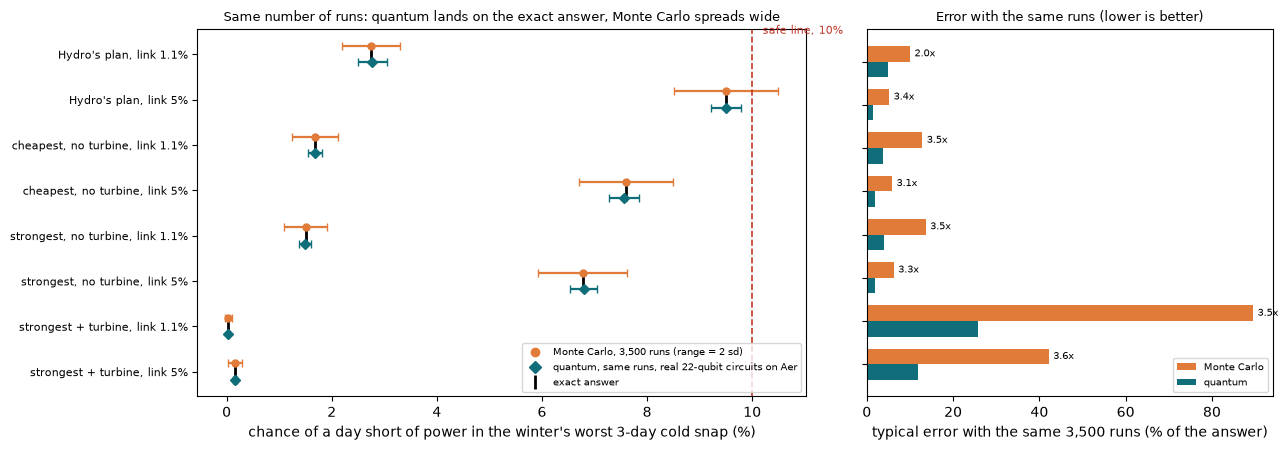

In [14]:
display(report.coldsnap_plans())
plots.show("coldsnap_plans")

**It works.** In all 8 checks the quantum estimate lands on the exact answer (for example 9.50% against 9.51% for
Hydro's plan with the link down 5%), and the measured result after every number of boosts matches theory, so the full
circuit behaves as designed.

**It needs fewer runs.** With the same 3,500 runs, the quantum estimate's error is 2 to 3.5 times smaller than Monte
Carlo's in every check. Because Monte Carlo's error only falls with the square root of the runs, matching that needs 4
to 12 times more Monte Carlo runs.

**It makes the hard call.** Hydro's plan with the link down 5% sits at 9.5%, just under the 10% line. With 3,500 runs,
quantum called it safe in 184 of 200 tries (the rest were "can't tell yet"). Monte Carlo managed it in 34 of 200.
Monte Carlo needs about 14,000 runs to make that call reliably; quantum about 1,900, 7 times fewer. Plans far from the
line are easy calls for both methods.

**Why this matters at full size.** Here exact enumeration is still possible. At 6 plants over 7 days it is already 1.8 ×
10<sup>13</sup> histories, while the circuit needs 16,690 two-qubit gates (section 11). At real size only sampling works,
and that is where these savings apply.

**Limits.** This is a simulated perfect quantum computer. The circuits have about 3,500 two-qubit gates before any boost,
far beyond today's chips, so this needs error-corrected hardware. A side finding: in a cold snap, the no-turbine plans
with heat pumps and wind are safer than Hydro's two projects (6.8% to 7.6% against 9.5% with the link down 5%); adding
the turbine to the strongest plan brings the risk under 0.2%.

## 13. What didn't work

* We tried a quantum-enhanced search (Layden et al., Nature 2023) to explore the 4,096 plans. It was slower than simply
  changing one option at a time in 41 of 45 exact tests, about 5 times slower in the median case. The cost landscape of
  these plans is smooth, and that kind of search only pays off on rugged ones.
* Deep circuits on the real chip: past about 30 two-qubit gates, the chip's errors outweigh what the extra boosts gain.
* Importance sampling, tuned well, is as good as amplitude estimation at 10% precision. The quantum edge only shows up
  when the decision needs more precision than that.
* No model we tried predicts the February 2023 flash-freeze record.
* For a single hour, an exact classical calculation is fast, and we use it as ground truth. The quantum method is aimed
  at models like the cold snap in sections 11 and 12, where that shortcut stops working.

## 14. Limitations

* The engine only checks whether there's enough capacity. It has no transmission limits (the Avalon lines matter when
  the link is down), no reservoir limits, no maintenance schedule, no battery charge tracking and no emergency imports
  over the Maritime Link. Hydro's studies include some of these, which is one reason our 2030 numbers for Hydro's plan
  look worse than theirs.
* We have four winters of demand data. The archived series sits about 200 MW above Hydro's public figures for the 2023
  and 2024 peaks, so we anchor demand to Hydro's own forecast for each year we study.
* Wind comes from reanalysis winds and a generic turbine with no icing, so it's optimistic.
* Costs other than the turbine, Unit 8 and the batteries are our assumptions.
* The quantum sample savings are for a noise-free machine. On today's hardware we reach a tie, and only with a 3-qubit
  circuit.

## 15. Reproducing this

Python 3.12 on Windows 11, CPU only. Package versions are pinned in `requirements.txt`. Unless a section says
hardware, quantum results come from Qiskit Aer (noiseless, or the IBM Heron `FakeFez` noise model).

```bash
python -m venv .venv && .venv/Scripts/activate        # Linux/macOS: source .venv/bin/activate
pip install -r requirements.txt
jupyter notebook notebook.ipynb
```

| Data | Source |
|---|---|
| Island demand, 5-minute, Sep 2022 to Nov 2026 | NL Hydro "Current Island Demand", archived by Statistics Canada / CCEI High-Frequency Electricity Data |
| Hourly weather 1980 to 2026 (St. John's, Gander, Corner Brook, three wind sites) | ERA5 reanalysis via the Open-Meteo archive |
| Plants, outage rates, link assumptions, the 2.8 h criterion, peak forecasts, project costs | NL Hydro filings to the Public Utilities Board (list below) |
| Heating shares; heat pump performance; emission factors | Statistics Canada 38-10-0286-01; NRCan, NRC and NEEP; ECCC |

All data is public and needs no keys. It is cached in `data/raw/` and downloaded again if missing.

| Script | What it produces |
|---|---|
| `experiments/e1_demand_model.py` | AI demand model and baselines (section 1) |
| `experiments/e2_reliability.py` | 46-winter replay, Hydro check, heat pumps (sections 2 to 4) |
| `experiments/e7_every_good_plan.py` | all 4,096 plans scored (section 5) |
| `experiments/turbine_decision.py` | link break-even and samples needed per decision (sections 5 and 9) |
| `experiments/e3_quantum_core.py` | 24-qubit circuit on Aer (section 8) |
| `experiments/e4_rarity_advantage.py` | samples at 10% precision (section 9) |
| `experiments/e5_hardware_scale.py` | 3-qubit circuits, noise model and IBM hardware (`--hardware`, `--twin`) (section 10) |
| `experiments/e6_cold_snap.py` | multi-day circuit (section 11) |
| `experiments/coldsnap_plans.py` | four plans through a cold snap: quantum vs Monte Carlo end to end (section 12) |

Random seeds are fixed in each script (demand model 7, E3 2026, E4 44, E5 55, E6 66, E7 1225, turbine decision 2030).

## 16. Sources

* NL Hydro filings to the Board of Commissioners of Public Utilities: 2024 Resource Adequacy Plan (Rev. 2, Aug 2024);
  2025 Near-Term Reliability Report (Nov 2025); Rolling 12-Month Asset Performance, Q3 2026; 2026-27 Winter Readiness
  Report (Oct 2026); 2025 Island Load Forecast; Avalon Combustion Turbine application (Rev. 1, Apr 2026); Effective Load
  Carrying Capability study (Dec 2025). NL Hydro notices on the January 2026 Power Warning.
* DarkNL: NL Hydro's briefing to the PUB, January 2014.
* Statistics Canada table 38-10-0286-01; NRCan heat pump guide; NRC cold-climate heat pump field test (2013); NEEP
  cold-climate heat pump specification v3.1; ECCC emission factors and large-facility emissions data.
* Brassard, Hoyer, Mosca and Tapp (2002), amplitude estimation. Suzuki et al. (2020), maximum-likelihood amplitude
  estimation. Tanaka et al. (2021), noise-aware amplitude estimation. Woerner and Egger (2019) and Egger et al. (2021),
  quantum risk analysis. Layden et al. (2023), quantum-enhanced Markov chain Monte Carlo.
* Qiskit, Qiskit Aer, Qiskit IBM Runtime, scikit-learn, NumPy, SciPy, pandas, Matplotlib.
* AI tools helped write parts of the code and text; the team reviewed all of it and can explain every part.